# code_025 · Learning curves and data value

**Book:** section 5.4. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_05_GUIDE.md), [execution evidence](../CHAPTER_05_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_025). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=525;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 525


<a id="size-curve"></a>
## Change training size while keeping the question fixed

Independent-member generator: y=.3+1.2*x+.4*sin(pi*x)+Gaussian noise sd .12 mm. A fixed cubic Legendre model fits nested training prefixes of sizes 12,24,48,96,192. Use 30 independently generated training pools and one fixed independent 400-member development set. Plot mean training/development MSE; the 10–90% band describes variability over training pools conditional on this development set, not a confidence interval for future populations. There is no hyperparameter search or final-outcome access.

**Predict:** must training error decrease as examples are added? Can a mean curve establish the value of the next individual observation?


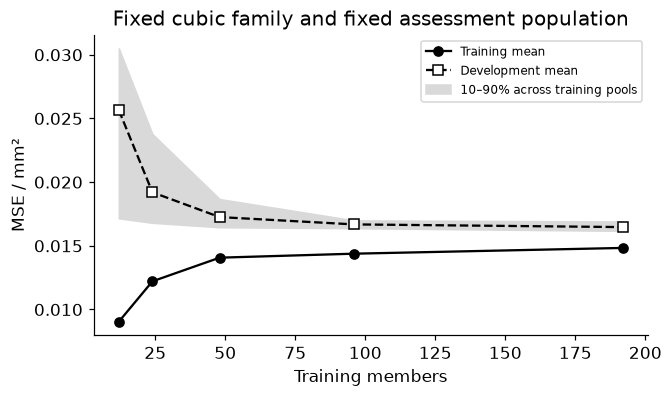

In [2]:
from numpy.polynomial.legendre import legvander
truth=lambda x:.3+1.2*x+.4*np.sin(np.pi*x)
sizes=np.array([12,24,48,96,192]);xd=rng.uniform(-1,1,400);yd=truth(xd)+rng.normal(0,.12,400);tr_errors=[];dv_errors=[]
for repeat in range(30):
 xx=rng.uniform(-1,1,192);yy=truth(xx)+rng.normal(0,.12,192);a=[];b=[]
 for n in sizes:
  X=legvander(xx[:n],3);w=np.linalg.lstsq(X,yy[:n],rcond=None)[0]
  a.append(np.mean((X@w-yy[:n])**2));b.append(np.mean((legvander(xd,3)@w-yd)**2))
 tr_errors.append(a);dv_errors.append(b)
tr_errors=np.array(tr_errors);dv_errors=np.array(dv_errors)
assert tr_errors.shape==dv_errors.shape==(30,5) and np.isfinite(dv_errors).all()
assert np.all(np.diff(sizes)>0) and sizes[-1]==192
fig,ax=plt.subplots(figsize=(6,3.5));ax.plot(sizes,tr_errors.mean(0),'ko-',label='Training mean');ax.plot(sizes,dv_errors.mean(0),'ks--',mfc='white',label='Development mean')
ax.fill_between(sizes,*np.quantile(dv_errors,[.1,.9],axis=0),color='.85',label='10–90% across training pools')
ax.set(xlabel='Training members',ylabel='MSE / mm²',title='Fixed cubic family and fixed assessment population');ax.legend(fontsize=8);plt.show()
RESULTS['training_sizes']=sizes.tolist();RESULTS['mean_development_MSE_mm2']=dv_errors.mean(0).tolist()


<a id="sites"></a>
## Separate repeated readings from independent buildings

Isolate the site effect by using known slope 1.5 and estimating only the population intercept. For G buildings and m readings per building, y=.4+1.5*x+b_g+epsilon, Var(b)=.65² and Var(epsilon)=.08². The fitted intercept is mean(y-1.5*x). Its variance is .65²/G+.08²/(G*m), exactly under independent zero-mean offsets/noises and balanced m. This deliberately known-slope experiment isolates sampling value; it is not a fitted full-response benchmark.

Use 400 replicates per design, G=4,12,36 and m=2,8,32. Prefixes are nested within each replicate. Estimate mean squared intercept error against the known generator mean .4. This simulator-only reference is not accessible in a field deployment. A flat curve in m does not imply that more sites are worthless.


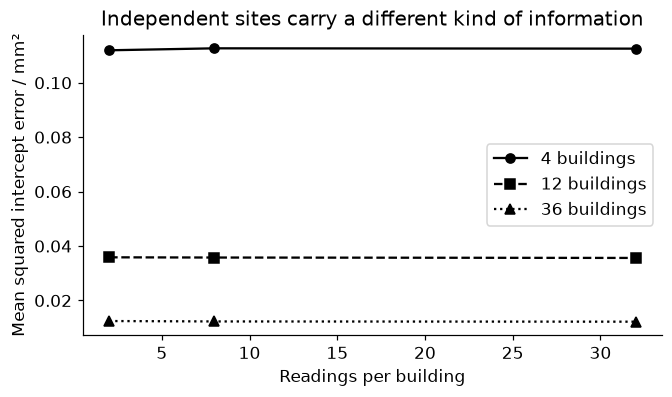

Monte Carlo / exact intercept MSE:


,2,8,32
4,0.111897,0.112619,0.112504
12,0.035850,0.035771,0.035623
36,0.012444,0.012296,0.012207


,2,8,32
4,0.106425,0.105825,0.105675
12,0.035475,0.035275,0.035225
36,0.011825,0.011758,0.011742


In [3]:
groups=[4,12,36];readings=[2,8,32];sums=np.zeros((3,3))
for repeat in range(400):
 offsets=rng.normal(0,.65,36);noise=rng.normal(0,.08,(36,32))
 for i,g in enumerate(groups):
  for j,m in enumerate(readings):
   intercept=.4+offsets[:g].mean()+noise[:g,:m].mean();sums[i,j]+=(intercept-.4)**2
observed=sums/400;theory=np.array([[.65**2/g+.08**2/(g*m) for m in readings] for g in groups])
assert observed.shape==(3,3) and np.all(observed>=0)
assert np.all(np.diff(theory,axis=0)<0) and np.all(np.diff(theory,axis=1)<0)
assert theory[0,2]>theory[2,0]
fig,ax=plt.subplots(figsize=(6,3.5))
for i,(g,style,marker) in enumerate(zip(groups,['-','--',':'],['o','s','^'])):ax.plot(readings,observed[i],color='black',ls=style,marker=marker,label=f'{g} buildings')
ax.set(xlabel='Readings per building',ylabel='Mean squared intercept error / mm²',title='Independent sites carry a different kind of information');ax.legend();plt.show()
print('Monte Carlo / exact intercept MSE:');display(pd.DataFrame(observed,index=groups,columns=readings));display(pd.DataFrame(theory,index=groups,columns=readings))
RESULTS['site_designs_observed_intercept_MSE_mm2']=observed.tolist();RESULTS['site_designs_exact_intercept_MSE_mm2']=theory.tolist()


<a id="coverage"></a>
## Coverage is not interchangeable with row count

Construct a ledger: 800 training readings from material A, zero from material B. Another 800 A readings increase row count without supplying direct evidence for B. The target workload here is half A and half B by building, not by readings. This is a coverage diagnostic, not an assertion that transfer is impossible. Domain knowledge or valid shared mechanisms could support transfer, but that would need its own evidence. Acquisition choices also require actual cost and consequence information; no cost advantage is inferred here.


In [4]:
coverage=pd.DataFrame({'material':['A','B'],'training_readings':[800,0],'target_building_fraction':[.5,.5]});display(coverage)
assert coverage.training_readings.sum()==800 and np.isclose(coverage.target_building_fraction.sum(),1)
assert coverage.loc[coverage.material=='B','training_readings'].item()==0
RESULTS['unobserved_target_material']='B'


,material,training_readings,target_building_fraction
0,A,800,0.5
1,B,0,0.5


<a id="final"></a>
## One fixed-rule final assessment

For the independent-member task only, freeze the declared cubic rule and n=192. Fit a new training pool, then generate 500 fresh final members. This is not a selected best replicate. The site-design simulation and coverage ledger do not use these final outcomes. Later model or acquisition choices require development evidence and fresh assessment.


In [5]:
xx=rng.uniform(-1,1,192);yy=truth(xx)+rng.normal(0,.12,192);w=np.linalg.lstsq(legvander(xx,3),yy,rcond=None)[0]
xf=rng.uniform(-1,1,500);yf=truth(xf)+rng.normal(0,.12,500);mse=float(np.mean((legvander(xf,3)@w-yf)**2))
assert np.isfinite(mse) and len(xf)==500
print('Fixed cubic, 192 training members; final MSE [mm²]:',mse);RESULTS['fixed_rule_final_MSE_mm2']=mse


Fixed cubic, 192 training members; final MSE [mm²]: 0.01568257757125146


<a id="exercises"></a>
## Exercises and hints

1. Repeat the independent-member curve using a line. Diagnose a possible family floor without treating curve shape as proof of its cause.
2. Give the development set only material A while deployment contains B. Explain why a good curve can answer the wrong question.
3. Compare 4×32 and 36×2 site designs, including independent-site counts and an explicit acquisition cost model.
4. Add a new sensor type whose measurement error differs. Decide whether its rows belong on the same learning curve.

**Hints:** ask what remains fixed: model, preprocessing, sample unit, split, population and metric. Curves condition on an acquisition scheme. Their extrapolation beyond observed sizes is another model assumption. See official [learning-curve guidance](https://scikit-learn.org/1.9/modules/learning_curve.html).


In [6]:
summary={'example_id':'code_025','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['nested training-size development curve', 'repeat-sample descriptive variability', 'readings versus independent sites', 'subgroup coverage and data value', 'sealed final fixed-rule assessment'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["nested training-size development curve", "repeat-sample descriptive variability", "readings versus independent sites", "subgroup coverage and data value", "sealed final fixed-rule assessment"], "elapsed_seconds": 0.168, "example_id": "code_025", "hardware": "Darwin arm64 CPU", "results": {"fixed_rule_final_MSE_mm2": 0.01568257757125146, "mean_development_MSE_mm2": [0.02565142908506948, 0.019197038138588633, 0.01725307107196982, 0.016677803101024843, 0.01646709131180197], "site_designs_exact_intercept_MSE_mm2": [[0.106425, 0.10582500000000002, 0.105675], [0.035475, 0.035275, 0.035225], [0.011825, 0.011758333333333334, 0.011741666666666668]], "site_designs_observed_intercept_MSE_mm2": [[0.11189743478118823, 0.11261901923746366, 0.11250413142910345], [0.035850252683769436, 0.035771295090195276, 0.03562279398771688], [0.012443778238251865, 0.012295583650888866, 0.01220654736661897]], "training_sizes": [12, 24, 48, 96, 192], "unobserved_tar